# Engine overheat alerts from 1-second telematics

Testing notebook for a **hybrid alerter**: a gradient-boosting model proposes a risk score, and a physics rule layer blocks alerts that do not look like a real cooling failure.

Each row is one second. The target is an early warning that coolant will sit at or above the overheat line long enough to count as an event.

**How to change things**

1. Edit the settings cell.
2. Run the notebook from the top.
3. To try new thresholds without retraining, use the last cell and set `USE_SANDBOX = True`.

Point `DATA_CSV` at your own file when you have one. Leave it as `None` to run the built-in 1 Hz fleet, which includes real overheats plus the usual false-alarm traps: sensor spikes, a drifting coolant sensor, hot-but-stable days, cold starts, and heat soaks that recover.

In [1]:
# ---------------------------------------------------------------------------
# Settings. Change these, then run the notebook from the top.
# ---------------------------------------------------------------------------

# Your 1-second file. None uses the built-in fleet.
DATA_CSV = None  # r"D:\Engine Overheating\telematics.csv"

# If your file already marks seconds where the engine IS overheating (1/0),
# name that column. The warning label is then the HORIZON_S seconds before each run.
LABEL_COLUMN = None

SEED = 42
N_TRIPS = 120          # built-in fleet size. Raise this for a steadier test score.
TEST_FRACTION = 0.20
VAL_FRACTION = 0.20

# Event: coolant at or above this temperature, held for SUSTAIN_S seconds.
# 108 C is a developing-overheat line, below a typical dash red zone.
COOLANT_EVENT_C = 108.0
EXTREME_C = 115.0
SUSTAIN_S = 15
HORIZON_S = 180        # warn this many seconds before the event starts
MIN_RECALL = 0.70      # validation will not trade below this event recall to cut false alarms

# Spike reject: a 1-second jump larger than this is not physically a coolant change.
SPIKE_C_PER_S = 5.0

# Rule points. Each true point adds 1 to rule_score.
RULE_COOLANT_C = 99.0
RULE_SLOPE_10 = 0.04       # C per second over 10 seconds
RULE_SLOPE_30 = 0.025
RULE_LOAD = 60.0
RULE_SPEED_MAX = 35.0      # km/h, paired with high load (poor airflow)
RULE_AMBIENT_GAP = 62.0
RULE_OIL_C = 108.0
RULE_PERSIST_POINT = 12    # seconds of hot-and-rising required to earn that point

# Hard vetoes. A vetoed second cannot alert.
VETO_COLD_C = 80.0
VETO_FALLING_SLOPE = -0.02
VETO_FALLING_BELOW_C = 107.0
VETO_CRUISE_SPEED = 50.0
VETO_CRUISE_LOAD = 40.0
VETO_CRUISE_SLOPE = 0.03
VETO_CRUISE_TEMP = 100.0

# Hybrid: ML probability must agree with the rules.
HYBRID_STRONG_COOLANT = 97.0
HYBRID_STRONG_SLOPE = 0.02
HYBRID_STRONG_SCORE = 2
HYBRID_CONFIRM_COOLANT = 96.0
HYBRID_CONFIRM_SCORE = 4
HYBRID_CONFIRM_PERSIST = 12

# An alert second counts only after it has been true for several seconds.
DEBOUNCE_NEED = 5
DEBOUNCE_WINDOW = 8
EPISODE_GAP_S = 40

# Leave these as None to take the validation operating point.
# Fill them in to lock a threshold and skip that search.
ML_THRESHOLD = None
HYBRID_TAU_HIGH = None
HYBRID_TAU_MID = None
RULE_MIN_SCORE = None
RULE_MIN_PERSIST = None

ML_TAU_GRID = [0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
HYBRID_TAU_HIGH_GRID = [0.70, 0.85, 0.92]
HYBRID_TAU_MID_GRID = [0.40, 0.55, 0.70]
RULE_SCORE_GRID = [3, 4, 5]
RULE_PERSIST_GRID = [8, 12, 20]

MODEL_PARAMS = dict(
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=31,
    min_samples_leaf=40,
    l2_regularization=0.1,
    class_weight="balanced",
    random_state=SEED,
)

## Data

Required columns when you bring your own file: `trip_id`, `coolant_temp_c`, `engine_rpm`, `engine_load_pct`, `vehicle_speed_kmh`. Add `timestamp` if you have it. One row is one second, in time order inside each trip.

These are used when present and filled with a neutral value when absent: `oil_temp_c`, `throttle_pct`, `intake_air_temp_c`, `ambient_temp_c`, `radiator_fan_on`, `ac_on`, `grade_pct`, `fuel_rate_lph`, `vehicle_id`.

`coolant_true_c` exists only on the built-in fleet. It is the physical temperature used to mark events, so a sensor spike is not labeled as an overheat. It is never a model input.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)

CORE_COLUMNS = ["trip_id", "coolant_temp_c", "engine_rpm", "engine_load_pct", "vehicle_speed_kmh"]

FEATURE_COLS = [
    "coolant_temp_c", "coolant_clean", "oil_temp_c", "engine_rpm", "engine_load_pct",
    "vehicle_speed_kmh", "throttle_pct", "intake_air_temp_c", "ambient_temp_c",
    "radiator_fan_on", "ac_on", "grade_pct", "fuel_rate_lph", "sensor_spike",
    "coolant_slope_10s", "coolant_slope_30s", "coolant_slope_60s",
    "coolant_mean_10s", "coolant_mean_30s", "coolant_mean_60s",
    "load_mean_30s", "load_mean_60s", "speed_mean_30s", "speed_mean_60s",
    "rpm_mean_30s", "grade_mean_30s", "throttle_mean_30s", "fan_mean_30s",
    "temp_above_ambient", "oil_minus_coolant", "low_airflow_load",
    "slope_accel_10s", "rising_persist_s", "sec_above_100_last_60s",
]


def _smooth_noise(rng, n, scale, win):
    kernel = np.ones(win) / win
    return np.convolve(rng.normal(0, scale, size=n), kernel, mode="same")


def _make_schedule(n, rng):
    speed = np.zeros(n)
    load = np.zeros(n)
    grade = np.zeros(n)
    i = 0
    prev_speed = float(rng.uniform(0, 40))
    while i < n:
        mode = rng.choice(["cruise", "idle", "accel", "hill", "city"])
        dur = int(rng.integers(25, 160))
        j = min(n, i + dur)
        span = j - i
        if mode == "cruise":
            target = rng.uniform(55, 100)
            speed[i:j] = np.linspace(prev_speed, target, span)
            load[i:j] = rng.uniform(22, 42)
            grade[i:j] = rng.normal(0, 0.5, size=span)
        elif mode == "idle":
            speed[i:j] = np.linspace(prev_speed, 0, span)
            load[i:j] = rng.uniform(8, 16)
            grade[i:j] = 0.0
        elif mode == "accel":
            target = rng.uniform(40, 90)
            speed[i:j] = np.linspace(prev_speed, target, span)
            load[i:j] = rng.uniform(65, 95)
            grade[i:j] = rng.normal(0, 0.8, size=span)
        elif mode == "hill":
            target = rng.uniform(28, 60)
            speed[i:j] = np.linspace(prev_speed, target, span)
            load[i:j] = rng.uniform(72, 96)
            grade[i:j] = rng.uniform(3, 8)
        else:
            target = rng.uniform(8, 35)
            speed[i:j] = np.linspace(prev_speed, target, span)
            load[i:j] = rng.uniform(18, 48)
            grade[i:j] = rng.normal(0, 1.0, size=span)
        prev_speed = float(speed[j - 1])
        i = j
    speed = np.clip(speed + _smooth_noise(rng, n, 1.2, 7), 0, 140)
    load = np.clip(load + _smooth_noise(rng, n, 2.5, 5), 0, 100)
    return speed, load, grade


def _apply_scenario(speed, load, grade, scenario, rng):
    n = len(speed)
    fan_eff = np.ones(n)
    leak = np.ones(n)
    ambient = np.full(n, float(rng.uniform(18, 32)))
    coolant0 = float(rng.uniform(86, 96))
    if scenario == "hot_stable":
        ambient[:] = rng.uniform(38, 44)
        coolant0 = rng.uniform(92, 99)
    elif scenario == "cold_start":
        coolant0 = rng.uniform(22, 45)
        ambient[:] = rng.uniform(8, 22)
    elif scenario == "overheat_traffic":
        ambient[:] = rng.uniform(36, 45)
        a = int(n * rng.uniform(0.35, 0.55))
        b = min(n, a + int(rng.integers(360, 560)))
        speed[a:b] = rng.uniform(0, 6, size=b - a)
        load[a:b] = rng.uniform(58, 82, size=b - a)
        fan_eff[a:b] = 0.08
        leak[a:b] = 0.40
    elif scenario == "overheat_fan_fail":
        ambient[:] = rng.uniform(33, 42)
        a = int(n * rng.uniform(0.25, 0.45))
        b = min(n, a + int(rng.integers(480, 780)))
        fan_eff[a:b] = 0.05
        leak[a:b] = 0.55
        speed[a:b] = rng.uniform(0, 10, size=b - a)
        load[a:b] = rng.uniform(55, 88, size=b - a)
    elif scenario == "overheat_climb":
        ambient[:] = rng.uniform(34, 43)
        a = int(n * rng.uniform(0.22, 0.40))
        b = min(n, a + int(rng.integers(420, 640)))
        speed[a:b] = rng.uniform(12, 28, size=b - a)
        load[a:b] = rng.uniform(88, 100, size=b - a)
        grade[a:b] = rng.uniform(6, 12)
        fan_eff[a:b] = 0.20
        leak[a:b] = 0.50
    elif scenario == "hill_ok":
        a = int(n * 0.4)
        b = min(n, a + int(rng.integers(90, 160)))
        speed[a:b] = rng.uniform(30, 50, size=b - a)
        load[a:b] = rng.uniform(80, 98, size=b - a)
        grade[a:b] = rng.uniform(5, 8)
    elif scenario == "heat_soak_recover":
        ambient[:] = rng.uniform(30, 40)
        a = int(n * rng.uniform(0.30, 0.55))
        b = min(n, a + int(rng.integers(70, 110)))
        speed[a:b] = rng.uniform(0, 8, size=b - a)
        load[a:b] = rng.uniform(60, 90, size=b - a)
        fan_eff[a:b] = 0.45
        leak[a:b] = 0.72
        if b < n:
            speed[b : min(n, b + 90)] = rng.uniform(45, 80)
            load[b : min(n, b + 90)] = rng.uniform(25, 40)
    return speed, load, grade, ambient, fan_eff, leak, coolant0


def _integrate(speed, load, ambient, ac, fan_eff, leak, coolant0):
    n = len(speed)
    coolant = np.empty(n)
    oil = np.empty(n)
    fan = np.zeros(n)
    rpm = 650 + load * 16.0 + speed * 18.0
    coolant[0] = coolant0
    oil[0] = coolant0 - 6 if coolant0 >= 70 else min(coolant0, ambient[0] + 8)
    for i in range(1, n):
        hot = coolant[i - 1] >= 97
        hold = fan[i - 1] == 1 and coolant[i - 1] >= 91
        fan[i] = 1.0 if hot or hold else 0.0
        airflow = 0.10 + 0.95 * (1 - np.exp(-speed[i] / 22.0))
        airflow += 0.75 * fan[i] * fan_eff[i]
        airflow *= leak[i]
        rpm_factor = 0.40 + min(rpm[i], 4800) / 4800
        heat = 0.010 + 0.085 * (load[i] / 100.0) * rpm_factor + 0.012 * ac[i]
        opening = float(np.clip((coolant[i - 1] - 84.0) / 8.0, 0.03, 1.0))
        cooling = 0.00115 * airflow * opening * max(coolant[i - 1] - ambient[i], 0.0)
        coolant[i] = coolant[i - 1] + float(np.clip(heat - cooling, -0.25, 0.20))
        oil_target = coolant[i] + 6 + 0.12 * load[i]
        oil[i] = oil[i - 1] + 0.05 * (oil_target - oil[i - 1])
    return coolant, oil, fan, rpm


def simulate_fleet(n_trips=N_TRIPS, seed=SEED):
    """1 Hz fleet. Scenarios that start with 'overheat' are the failures to catch."""
    weights = {
        "normal": 0.28,
        "hot_stable": 0.12,
        "cold_start": 0.10,
        "spike_noise": 0.10,
        "sensor_bias": 0.08,
        "hill_ok": 0.08,
        "heat_soak_recover": 0.10,
        "overheat_traffic": 0.08,
        "overheat_fan_fail": 0.08,
        "overheat_climb": 0.06,
    }
    rng = np.random.default_rng(seed)
    names = list(weights)
    probs = np.array(list(weights.values()), dtype=float)
    probs = probs / probs.sum()
    frames = []
    base = pd.Timestamp("2026-01-05 06:00:00")
    for trip_id in range(n_trips):
        scenario = str(rng.choice(names, p=probs))
        n = int(rng.integers(14 * 60, 24 * 60))
        speed, load, grade = _make_schedule(n, rng)
        speed, load, grade, ambient, fan_eff, leak, coolant0 = _apply_scenario(speed, load, grade, scenario, rng)
        ac = np.zeros(n)
        cursor = 0
        ac_rate = 0.55 if scenario.startswith("overheat") or scenario == "hot_stable" else 0.25
        while cursor < n:
            span = int(rng.integers(60, 240))
            ac[cursor : min(n, cursor + span)] = 1.0 if rng.random() < ac_rate else 0.0
            cursor += span
        coolant, oil, fan, rpm = _integrate(speed, load, ambient, ac, fan_eff, leak, coolant0)
        measured = coolant + rng.normal(0, 0.15, size=n)
        if scenario == "spike_noise":
            for _ in range(int(rng.integers(4, 9))):
                s0 = int(rng.integers(40, n - 4))
                width = int(rng.integers(1, 3))
                measured[s0 : s0 + width] += rng.uniform(12, 30)
        elif scenario == "sensor_bias":
            a = int(rng.integers(int(n * 0.2), int(n * 0.6)))
            rise = int(rng.integers(20, 40))
            hold = int(rng.integers(70, 140))
            bias = float(rng.uniform(10, 16))
            measured[a : a + rise] += np.linspace(0, bias, rise)[: max(0, min(rise, n - a))]
            measured[a + rise : min(n, a + rise + hold)] += bias
        ts = base + pd.Timedelta(minutes=45 * trip_id) + pd.to_timedelta(np.arange(n), unit="s")
        frames.append(pd.DataFrame({
            "timestamp": ts,
            "vehicle_id": f"V{trip_id % 40:03d}",
            "trip_id": f"T{trip_id:04d}",
            "coolant_temp_c": measured,
            "coolant_true_c": coolant,
            "oil_temp_c": oil + rng.normal(0, 0.15, size=n),
            "engine_rpm": rpm,
            "engine_load_pct": load,
            "vehicle_speed_kmh": speed,
            "throttle_pct": np.clip(load + rng.normal(0, 3, size=n), 0, 100),
            "intake_air_temp_c": ambient + 4 + 0.07 * load + rng.normal(0, 0.3, size=n),
            "ambient_temp_c": ambient,
            "radiator_fan_on": fan.astype(int),
            "ac_on": ac.astype(int),
            "grade_pct": grade,
            "fuel_rate_lph": np.clip(0.5 + (load / 100) * (rpm / 850) + rng.normal(0, 0.05, size=n), 0, None),
            "scenario": scenario,
        }))
    return pd.concat(frames, ignore_index=True)


def load_telematics(path):
    df = pd.read_csv(path)
    missing = [c for c in CORE_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError(f"CSV is missing required columns: {missing}")
    if "timestamp" in df.columns:
        df["timestamp"] = pd.to_datetime(df["timestamp"])
    else:
        df["timestamp"] = df.groupby("trip_id").cumcount()
    if "vehicle_id" not in df.columns:
        df["vehicle_id"] = df["trip_id"]
    if "scenario" not in df.columns:
        df["scenario"] = "uploaded"
    if "oil_temp_c" not in df.columns:
        df["oil_temp_c"] = df["coolant_temp_c"]
    if "throttle_pct" not in df.columns:
        df["throttle_pct"] = df["engine_load_pct"]
    if "ambient_temp_c" not in df.columns:
        df["ambient_temp_c"] = 25.0
    if "intake_air_temp_c" not in df.columns:
        df["intake_air_temp_c"] = df["ambient_temp_c"]
    if "radiator_fan_on" not in df.columns:
        df["radiator_fan_on"] = 0
    if "ac_on" not in df.columns:
        df["ac_on"] = 0
    if "grade_pct" not in df.columns:
        df["grade_pct"] = 0.0
    if "fuel_rate_lph" not in df.columns:
        df["fuel_rate_lph"] = 0.0
    filled = [c for c in ["oil_temp_c", "throttle_pct", "ambient_temp_c", "intake_air_temp_c",
                          "radiator_fan_on", "ac_on", "grade_pct", "fuel_rate_lph"]
              if c not in pd.read_csv(path, nrows=0).columns]
    if filled:
        print("Filled missing columns with neutral values:", filled)
    return df


raw = load_telematics(DATA_CSV) if DATA_CSV else simulate_fleet(N_TRIPS, SEED)
print(f"{len(raw):,} seconds, {raw['trip_id'].nunique()} trips")
print(raw.groupby("scenario").size().rename("seconds").to_frame())
raw.head(3)

140,493 seconds, 120 trips
                   seconds
scenario                  
cold_start           10432
heat_soak_recover     5729
hill_ok              11217
hot_stable           14753
normal               35387
overheat_climb        6183
overheat_fan_fail     6148
overheat_traffic     16251
sensor_bias          12253
spike_noise          22140


,timestamp,vehicle_id,trip_id,coolant_temp_c,coolant_true_c,oil_temp_c,engine_rpm,engine_load_pct,vehicle_speed_kmh,throttle_pct,intake_air_temp_c,ambient_temp_c,radiator_fan_on,ac_on,grade_pct,fuel_rate_lph,scenario
0,2026-01-05 06:00:00,V000,T0000,89.378565,89.386956,83.422967,2776.741953,93.978171,34.616179,88.307054,43.642597,32.280794,0,0,0.102272,3.537501,heat_soak_recover
1,2026-01-05 06:00:01,V000,T0000,89.098183,89.437065,84.507667,2773.865875,93.685145,34.716864,95.208130,42.666451,32.280794,0,0,-0.252994,3.580741,heat_soak_recover
2,2026-01-05 06:00:02,V000,T0000,89.519196,89.486870,85.774509,2777.056419,93.767305,34.821085,96.663331,43.293169,32.280794,0,0,-0.013441,3.553897,heat_soak_recover


## Labels and features

An event starts when repaired coolant stays at `COOLANT_EVENT_C` for `SUSTAIN_S` seconds, or touches `EXTREME_C`. A one-second spike is repaired out before that test.

`y_warn` is 1 on the `HORIZON_S` seconds before the event. Seconds inside the event are left blank so the model is trained to warn early, not to recognize an engine that is already over the line.

Slopes and rolling means use only past seconds. `coolant_clean` holds the last good sample across a spike so a single bad reading does not stay in the 60-second features.

In [3]:
def causal_despike(values, limit):
    y = np.asarray(values, dtype=float).copy()
    for i in range(1, len(y)):
        if abs(y[i] - y[i - 1]) > limit:
            y[i] = y[i - 1]
    return y


def consecutive_true(flag):
    flag = np.asarray(flag, dtype=int)
    out = np.zeros(len(flag), dtype=int)
    for i, bit in enumerate(flag):
        out[i] = (out[i - 1] + 1) if bit and i else int(bit)
    return out


def _hot_spans(hot, repaired=None):
    spans = []
    i = 0
    n = len(hot)
    while i < n:
        if not hot[i]:
            i += 1
            continue
        j = i + 1
        while j < n and hot[j]:
            j += 1
        long_enough = (j - i) >= SUSTAIN_S
        extreme = repaired is not None and float(np.max(repaired[i:j])) >= EXTREME_C
        if long_enough or extreme or repaired is None:
            spans.append((i, j - 1))
        i = j
    return spans


def build_features(df):
    pieces = []
    event_rows = []
    for trip_id, g in df.groupby("trip_id", sort=False):
        g = g.sort_values("timestamp").copy()
        raw_c = g["coolant_temp_c"].to_numpy(dtype=float)
        clean = causal_despike(raw_c, SPIKE_C_PER_S)
        g["coolant_clean"] = clean
        step = np.diff(raw_c, prepend=raw_c[0])
        g["sensor_spike"] = (np.abs(step) > SPIKE_C_PER_S).astype(int)

        if LABEL_COLUMN and LABEL_COLUMN in g.columns:
            hot = g[LABEL_COLUMN].fillna(0).to_numpy().astype(bool)
            spans = _hot_spans(hot, repaired=None)
        else:
            truth = g["coolant_true_c"].to_numpy(dtype=float) if "coolant_true_c" in g.columns else raw_c
            repaired = pd.Series(truth).rolling(5, center=True, min_periods=1).median().to_numpy()
            spans = _hot_spans(repaired >= COOLANT_EVENT_C, repaired)

        y = np.zeros(len(g), dtype=float)
        in_event = np.zeros(len(g), dtype=bool)
        scenario = g["scenario"].iloc[0] if "scenario" in g.columns else "uploaded"
        for start, end in spans:
            in_event[start : end + 1] = True
            y[max(0, start - HORIZON_S) : start] = 1.0
            event_rows.append({"trip_id": trip_id, "onset_s": start, "end_s": end, "scenario": scenario})
        y[in_event] = np.nan
        g["y_warn"] = y
        g["in_event"] = in_event

        s = pd.Series(clean, index=g.index)
        g["coolant_slope_10s"] = (s - s.shift(10)) / 10
        g["coolant_slope_30s"] = (s - s.shift(30)) / 30
        g["coolant_slope_60s"] = (s - s.shift(60)) / 60
        g["coolant_mean_10s"] = s.rolling(10, min_periods=5).mean()
        g["coolant_mean_30s"] = s.rolling(30, min_periods=10).mean()
        g["coolant_mean_60s"] = s.rolling(60, min_periods=20).mean()
        g["load_mean_30s"] = g["engine_load_pct"].rolling(30, min_periods=10).mean()
        g["load_mean_60s"] = g["engine_load_pct"].rolling(60, min_periods=20).mean()
        g["speed_mean_30s"] = g["vehicle_speed_kmh"].rolling(30, min_periods=10).mean()
        g["speed_mean_60s"] = g["vehicle_speed_kmh"].rolling(60, min_periods=20).mean()
        g["rpm_mean_30s"] = g["engine_rpm"].rolling(30, min_periods=10).mean()
        g["grade_mean_30s"] = g["grade_pct"].rolling(30, min_periods=10).mean()
        g["throttle_mean_30s"] = g["throttle_pct"].rolling(30, min_periods=10).mean()
        g["fan_mean_30s"] = g["radiator_fan_on"].rolling(30, min_periods=10).mean()
        g["temp_above_ambient"] = g["coolant_clean"] - g["ambient_temp_c"]
        g["oil_minus_coolant"] = g["oil_temp_c"] - g["coolant_clean"]
        g["low_airflow_load"] = g["load_mean_30s"] * np.exp(-g["speed_mean_30s"] / 25.0)
        g["slope_accel_10s"] = g["coolant_slope_10s"] - g["coolant_slope_10s"].shift(10)
        rising = ((g["coolant_clean"] >= 98) & (g["coolant_slope_10s"] >= 0.02)).fillna(False).to_numpy()
        g["rising_persist_s"] = consecutive_true(rising)
        above = (g["coolant_clean"] >= 100).astype(float)
        g["sec_above_100_last_60s"] = above.rolling(60, min_periods=10).sum()
        pieces.append(g)

    feat = pd.concat(pieces, ignore_index=True)
    events = pd.DataFrame(event_rows)
    return feat, events


feat, events = build_features(raw)
print(f"Events: {len(events)}")
print(f"Warning seconds: {int((feat['y_warn'] == 1).sum()):,}  |  normal seconds: {int((feat['y_warn'] == 0).sum()):,}")
if len(events):
    display(events.groupby("scenario").size().rename("events").to_frame())

Events: 24
Warning seconds: 4,320  |  normal seconds: 128,459


,events
scenario,
overheat_climb,5
overheat_fan_fail,5
overheat_traffic,14


## Rules, model, hybrid

**Rules** add a point for a hot coolant, a real climb, high load with low road speed, a large gap over ambient, hot oil, or a fan that is already on in traffic while temperature is still rising. A second is vetoed when the reading jumps, the engine is still cold, temperature is already falling, or the indicated temperature is high during an easy cruise (sensor offset, not a cooling failure).

**Model** is a histogram gradient booster. Trips are split so seconds from the same trip never sit in both train and test. The fit uses warning-window seconds only.

**Hybrid** alerts when the model is confident and the coolant is actually climbing with some rule support, or when the model is moderately confident and the rules have been true long enough. A veto always wins. The debounce asks the condition to hold for several seconds before the alert counts.

In [4]:
def add_rule_columns(df):
    c = df["coolant_clean"]
    slope10 = df["coolant_slope_10s"].fillna(0)
    slope30 = df["coolant_slope_30s"].fillna(0)
    load30 = df["load_mean_30s"].fillna(0)
    speed30 = df["speed_mean_30s"].fillna(0)
    points = [
        c >= RULE_COOLANT_C,
        slope10 >= RULE_SLOPE_10,
        slope30 >= RULE_SLOPE_30,
        (load30 >= RULE_LOAD) & (speed30 <= RULE_SPEED_MAX),
        (df["temp_above_ambient"] >= RULE_AMBIENT_GAP) & (slope30 > 0.01),
        (df["oil_temp_c"] >= RULE_OIL_C) & (slope10 > 0.02),
        df["rising_persist_s"].fillna(0) >= RULE_PERSIST_POINT,
        (df["fan_mean_30s"].fillna(0) >= 0.6) & (speed30 <= 15) & (load30 >= 45) & (slope30 > 0.02),
    ]
    out = df.copy()
    out["rule_score"] = np.sum([p.astype(int) for p in points], axis=0)
    cruise_offset = (
        (speed30 >= VETO_CRUISE_SPEED)
        & (load30 <= VETO_CRUISE_LOAD)
        & (slope10 <= VETO_CRUISE_SLOPE)
        & (c >= VETO_CRUISE_TEMP)
    )
    out["rule_veto"] = (
        (out["sensor_spike"] == 1)
        | (c < VETO_COLD_C)
        | ((slope30 < VETO_FALLING_SLOPE) & (c < VETO_FALLING_BELOW_C))
        | cruise_offset
    )
    return out


def split_trips(df, seed=SEED):
    meta = df.groupby("trip_id", sort=False).agg(has_event=("in_event", "max")).reset_index()
    rng = np.random.default_rng(seed)
    train, val, test = [], [], []
    for _, part in meta.groupby("has_event"):
        ids = part["trip_id"].to_numpy().copy()
        rng.shuffle(ids)
        n = len(ids)
        n_test = int(round(n * TEST_FRACTION))
        n_val = int(round(n * VAL_FRACTION))
        if n >= 5 and n_test + n_val >= n:
            n_test = max(1, n // 5)
            n_val = max(1, n // 5)
        if n < 5:
            n_test = 1 if n >= 3 else 0
            n_val = 1 if n >= 4 else 0
        test.extend(ids[:n_test])
        val.extend(ids[n_test : n_test + n_val])
        train.extend(ids[n_test + n_val :])
    return set(train), set(val), set(test)


def debounce(flag, need=None, window=None):
    need = DEBOUNCE_NEED if need is None else need
    window = DEBOUNCE_WINDOW if window is None else window
    flag = np.asarray(flag, dtype=float)
    rolled = pd.Series(flag).rolling(window, min_periods=1).sum().to_numpy()
    return rolled >= need


def episodes(mask, gap=None):
    gap = EPISODE_GAP_S if gap is None else gap
    idx = np.flatnonzero(np.asarray(mask, dtype=bool))
    if len(idx) == 0:
        return []
    starts = [int(idx[0])]
    ends = []
    for a, b in zip(idx[:-1], idx[1:]):
        if b - a > gap:
            ends.append(int(a))
            starts.append(int(b))
    ends.append(int(idx[-1]))
    return list(zip(starts, ends))


def score_alerts(alert, spans, n_seconds):
    found = episodes(alert)
    detected = 0
    early = 0
    leads = []
    for start, end in spans:
        hits = [s for s, e in found if e >= start - HORIZON_S and s <= end]
        if not hits:
            continue
        detected += 1
        lead = start - min(hits)
        leads.append(lead)
        early += int(lead > 0)
    fp = 0
    for s, e in found:
        covered = any(e >= start - HORIZON_S and s <= end for start, end in spans)
        fp += int(not covered)
    hours = n_seconds / 3600.0
    return {
        "events": len(spans),
        "detected": detected,
        "early": early,
        "leads": leads,
        "fp_episodes": fp,
        "alert_episodes": len(found),
        "hours": hours,
    }


def pack_trips(df):
    packed = {}
    for trip_id, g in df.groupby("trip_id", sort=False):
        g = g.sort_values("timestamp")
        in_event = g["in_event"].to_numpy()
        spans = []
        i = 0
        while i < len(g):
            if not in_event[i]:
                i += 1
                continue
            j = i + 1
            while j < len(g) and in_event[j]:
                j += 1
            spans.append((i, j - 1))
            i = j
        packed[trip_id] = {
            "n": len(g),
            "spans": spans,
            "scenario": g["scenario"].iloc[0] if "scenario" in g.columns else "uploaded",
            "proba": g["proba"].to_numpy(),
            "rule_score": g["rule_score"].to_numpy(),
            "rule_veto": g["rule_veto"].to_numpy().astype(bool),
            "persist": g["rising_persist_s"].fillna(0).to_numpy(),
            "coolant": g["coolant_clean"].to_numpy(),
            "slope30": g["coolant_slope_30s"].fillna(0).to_numpy(),
        }
    return packed


def evaluate(packed, alert_fn):
    totals = {k: 0 for k in ["events", "detected", "early", "fp_episodes", "alert_episodes"]}
    totals["hours"] = 0.0
    leads = []
    by_scenario = {}
    for trip in packed.values():
        stats = score_alerts(alert_fn(trip), trip["spans"], trip["n"])
        for key in ["events", "detected", "early", "fp_episodes", "alert_episodes", "hours"]:
            totals[key] += stats[key]
        leads.extend(stats["leads"])
        bucket = by_scenario.setdefault(trip["scenario"], {"fp": 0, "events": 0, "detected": 0, "hours": 0.0})
        bucket["fp"] += stats["fp_episodes"]
        bucket["events"] += stats["events"]
        bucket["detected"] += stats["detected"]
        bucket["hours"] += stats["hours"]
    recall = totals["detected"] / totals["events"] if totals["events"] else np.nan
    precision = (
        (totals["alert_episodes"] - totals["fp_episodes"]) / totals["alert_episodes"]
        if totals["alert_episodes"] else np.nan
    )
    return {
        "recall": recall,
        "early_recall": totals["early"] / totals["events"] if totals["events"] else np.nan,
        "precision": precision,
        "fp_per_hour": totals["fp_episodes"] / totals["hours"] if totals["hours"] else np.nan,
        "fp_episodes": totals["fp_episodes"],
        "detected": totals["detected"],
        "events": totals["events"],
        "median_lead_s": float(np.median(leads)) if leads else np.nan,
        "by_scenario": by_scenario,
    }


def _params(overrides=None):
    # Defaults let the validation search run before CHOSEN exists.
    # The grid spec overwrites the keys it is testing.
    chosen = {
        "ml_tau": 0.5,
        "tau_high": 0.8,
        "tau_mid": 0.5,
        "rule_score": 4,
        "rule_persist": 12,
    }
    if "CHOSEN" in globals():
        chosen.update(CHOSEN)
    if overrides:
        chosen.update({k: v for k, v in overrides.items() if v is not None})
    return chosen


def ml_alert(trip, overrides=None):
    tau = _params(overrides)["ml_tau"]
    return debounce(trip["proba"] >= tau)


def rule_alert(trip, overrides=None):
    p = _params(overrides)
    raw = (
        (trip["rule_score"] >= p["rule_score"])
        & (trip["persist"] >= p["rule_persist"])
        & (trip["coolant"] >= HYBRID_STRONG_COOLANT)
        & ~trip["rule_veto"]
    )
    return debounce(raw)


def hybrid_alert(trip, overrides=None):
    p = _params(overrides)
    strong = (
        (trip["proba"] >= p["tau_high"])
        & (trip["coolant"] >= HYBRID_STRONG_COOLANT)
        & (trip["slope30"] >= HYBRID_STRONG_SLOPE)
        & (trip["rule_score"] >= HYBRID_STRONG_SCORE)
    )
    confirmed = (
        (trip["proba"] >= p["tau_mid"])
        & (trip["rule_score"] >= HYBRID_CONFIRM_SCORE)
        & (trip["persist"] >= HYBRID_CONFIRM_PERSIST)
        & (trip["coolant"] >= HYBRID_CONFIRM_COOLANT)
    )
    return debounce((strong | confirmed) & ~trip["rule_veto"])


def _pick(rows):
    eligible = [r for r in rows if r["recall"] >= MIN_RECALL]
    pool = eligible or rows
    def key(r):
        lead = r["median_lead_s"] if pd.notna(r["median_lead_s"]) else -1e9
        return (r["fp_per_hour"], -r["recall"], -lead)
    return sorted(pool, key=key)[0]


def _search_table(packed, candidates, alert_from_row):
    rows = []
    for spec in candidates:
        stats = evaluate(packed, lambda trip, spec=spec: alert_from_row(trip, spec))
        row = dict(spec)
        row.update({k: stats[k] for k in ["recall", "early_recall", "precision", "fp_per_hour", "median_lead_s", "fp_episodes", "detected", "events"]})
        rows.append(row)
    return rows


feat = add_rule_columns(feat)
train_ids, val_ids, test_ids = split_trips(feat)
feat["split"] = np.where(feat["trip_id"].isin(train_ids), "train", np.where(feat["trip_id"].isin(val_ids), "val", "test"))

train = feat[(feat["split"] == "train") & feat["y_warn"].notna()].copy()
print(f"Train seconds {len(train):,} | warning seconds {int(train['y_warn'].sum()):,}")
print(feat.groupby("split")["trip_id"].nunique().rename("trips").to_frame())

model = HistGradientBoostingClassifier(**MODEL_PARAMS)
model.fit(train[FEATURE_COLS], train["y_warn"].astype(int))
feat["proba"] = model.predict_proba(feat[FEATURE_COLS])[:, 1]

val_mask = (feat["split"] == "val") & feat["y_warn"].notna()
val_ap = average_precision_score(feat.loc[val_mask, "y_warn"].astype(int), feat.loc[val_mask, "proba"])
print(f"Validation average precision (second level): {val_ap:.3f}")

val_packed = pack_trips(feat[feat["split"] == "val"])
test_packed = pack_trips(feat[feat["split"] == "test"])

ml_rows = _search_table(val_packed, [{"ml_tau": t} for t in ML_TAU_GRID], lambda trip, spec: debounce(trip["proba"] >= spec["ml_tau"]))
rule_rows = _search_table(
    val_packed,
    [{"rule_score": s, "rule_persist": p} for s in RULE_SCORE_GRID for p in RULE_PERSIST_GRID],
    lambda trip, spec: rule_alert(trip, spec),
)
hy_rows = _search_table(
    val_packed,
    [{"tau_high": hi, "tau_mid": mid} for hi in HYBRID_TAU_HIGH_GRID for mid in HYBRID_TAU_MID_GRID],
    lambda trip, spec: hybrid_alert(trip, spec),
)

best_ml = _pick(ml_rows)
best_rule = _pick(rule_rows)
best_hy = _pick(hy_rows)
CHOSEN = {
    "ml_tau": ML_THRESHOLD if ML_THRESHOLD is not None else best_ml["ml_tau"],
    "tau_high": HYBRID_TAU_HIGH if HYBRID_TAU_HIGH is not None else best_hy["tau_high"],
    "tau_mid": HYBRID_TAU_MID if HYBRID_TAU_MID is not None else best_hy["tau_mid"],
    "rule_score": RULE_MIN_SCORE if RULE_MIN_SCORE is not None else best_rule["rule_score"],
    "rule_persist": RULE_MIN_PERSIST if RULE_MIN_PERSIST is not None else best_rule["rule_persist"],
}
print("Operating point:", CHOSEN)

link = train[FEATURE_COLS + ["y_warn"]].corr(numeric_only=True)["y_warn"].drop("y_warn").sort_values()
print("\nFeature correlation with the warning label (train):")
display(link.rename("corr_with_y_warn").to_frame().tail(12).round(3))

Train seconds 78,208 | warning seconds 2,520


       trips
split       
test      24
train     72
val       24


Validation average precision (second level): 0.984
Operating point: {'ml_tau': 0.4, 'tau_high': 0.7, 'tau_mid': 0.4, 'rule_score': 3, 'rule_persist': 20}



Feature correlation with the warning label (train):


,corr_with_y_warn
coolant_slope_10s,0.197
coolant_temp_c,0.203
oil_temp_c,0.219
ambient_temp_c,0.239
coolant_slope_30s,0.241
intake_air_temp_c,0.261
coolant_slope_60s,0.273
sec_above_100_last_60s,0.376
fan_mean_30s,0.520
radiator_fan_on,0.520


## Test result

Scores below are **event** scores on trips the model did not train on.

- **Recall**: share of overheat events with an alert in the warning window or during the event.
- **Early recall**: share alerted before the coolant crossed the line.
- **Precision**: share of alert episodes that belong to a real event.
- **False alarms per hour**: alert episodes with no event nearby. This is the number to push down.
- **Median lead**: seconds between the alert and the start of the event. Positive means the alert came first.

In [5]:
def show_test_report(overrides=None, packed=None):
    packed = test_packed if packed is None else packed
    summary = []
    detail = []
    for name, fn in [("rules", rule_alert), ("ml", ml_alert), ("hybrid", hybrid_alert)]:
        stats = evaluate(packed, lambda trip, fn=fn: fn(trip, overrides))
        summary.append({
            "model": name,
            "recall": stats["recall"],
            "early_recall": stats["early_recall"],
            "precision": stats["precision"],
            "false_alarms_per_hour": stats["fp_per_hour"],
            "false_alarms": stats["fp_episodes"],
            "events_caught": f"{stats['detected']}/{stats['events']}",
            "median_lead_s": stats["median_lead_s"],
        })
        for scenario, bucket in stats["by_scenario"].items():
            detail.append({
                "model": name,
                "scenario": scenario,
                "false_alarms": bucket["fp"],
                "events": bucket["events"],
                "caught": bucket["detected"],
                "hours": round(bucket["hours"], 2),
            })
    summary_df = pd.DataFrame(summary).set_index("model")
    detail_df = pd.DataFrame(detail)
    display(summary_df.round(3))
    display(detail_df.pivot(index="scenario", columns="model", values="false_alarms").fillna(0).astype(int))
    return summary_df, detail_df


summary_df, detail_df = show_test_report()

,recall,early_recall,precision,false_alarms_per_hour,false_alarms,events_caught,median_lead_s
model,,,,,,,
rules,1.0,1.0,1.0,0.0,0,5/5,123.0
ml,1.0,1.0,1.0,0.0,0,5/5,174.0
hybrid,1.0,1.0,1.0,0.0,0,5/5,172.0


model,hybrid,ml,rules
scenario,,,
hill_ok,0,0,0
hot_stable,0,0,0
normal,0,0,0
overheat_climb,0,0,0
overheat_fan_fail,0,0,0
overheat_traffic,0,0,0
sensor_bias,0,0,0
spike_noise,0,0,0


## One overheat trip and one false-alarm trap

The shaded band on the temperature chart is the actual overheat. The shaded band on the probability chart is the hybrid alert. Use these plots to see whether a threshold change fires too early, too late, or on a spike.

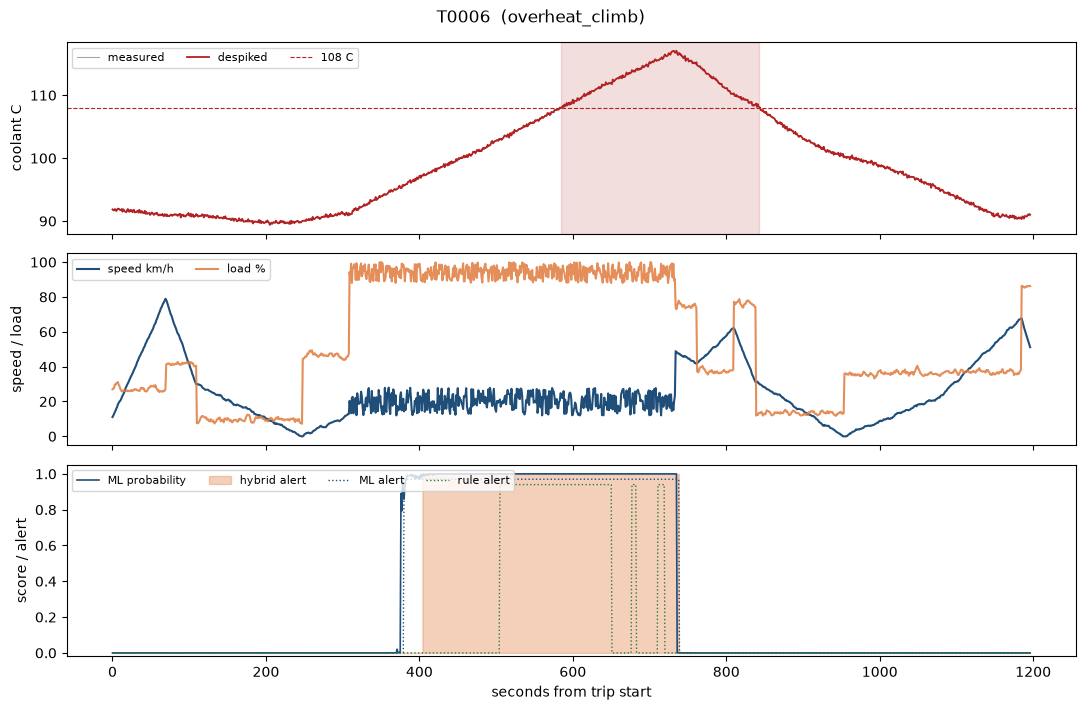

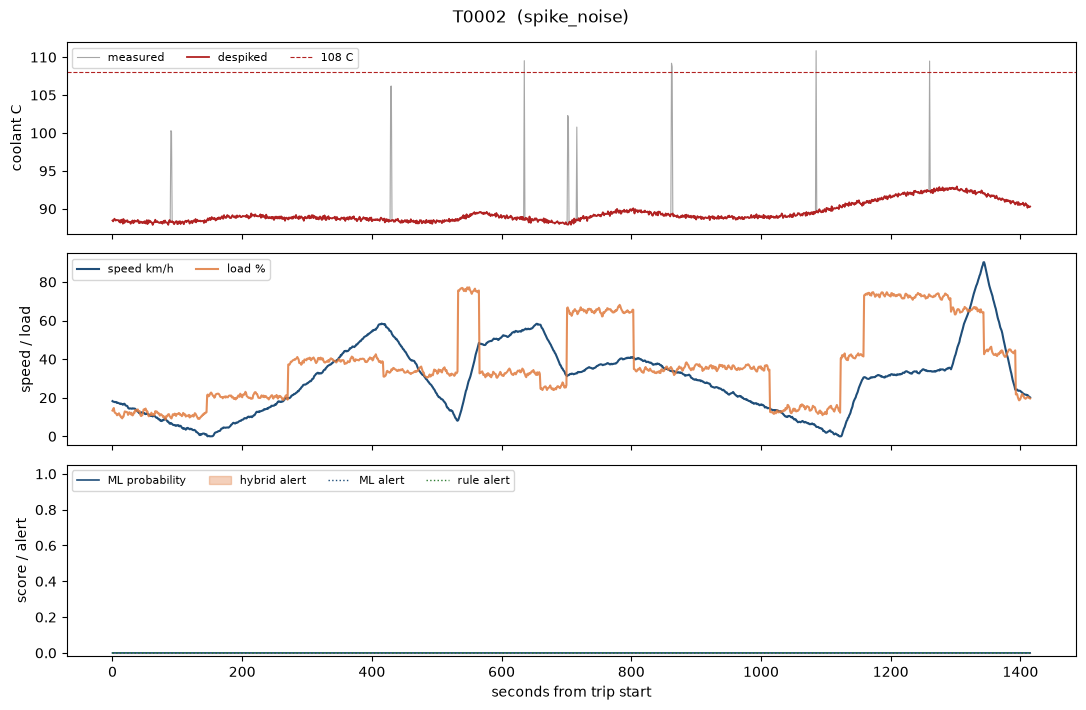

In [6]:
def plot_trip(trip_id):
    g = feat[feat["trip_id"] == trip_id].sort_values("timestamp")
    trip = pack_trips(g)[trip_id]
    t = np.arange(trip["n"])
    hybrid = hybrid_alert(trip).astype(float)
    rules = rule_alert(trip).astype(float)
    ml = ml_alert(trip).astype(float)
    fig, axes = plt.subplots(3, 1, figsize=(11, 7.2), sharex=True)
    axes[0].plot(t, g["coolant_temp_c"].to_numpy(), color="0.65", lw=0.8, label="measured")
    axes[0].plot(t, trip["coolant"], color="#b22222", lw=1.3, label="despiked")
    axes[0].axhline(COOLANT_EVENT_C, color="#b22222", ls="--", lw=0.8, label=f"{COOLANT_EVENT_C:.0f} C")
    for start, end in trip["spans"]:
        axes[0].axvspan(start, end, color="#b22222", alpha=0.15)
    axes[0].set_ylabel("coolant C")
    axes[0].legend(loc="upper left", ncol=3, fontsize=8)
    axes[1].plot(t, g["vehicle_speed_kmh"].to_numpy(), label="speed km/h", color="#1f4e79")
    axes[1].plot(t, g["engine_load_pct"].to_numpy(), label="load %", color="#e07a3d", alpha=0.85)
    axes[1].set_ylabel("speed / load")
    axes[1].legend(loc="upper left", ncol=2, fontsize=8)
    axes[2].plot(t, trip["proba"], color="#1f4e79", lw=1.2, label="ML probability")
    axes[2].fill_between(t, 0, hybrid, step="pre", color="#e07a3d", alpha=0.35, label="hybrid alert")
    axes[2].plot(t, ml * 0.97, color="#1f4e79", ls=":", lw=1, label="ML alert")
    axes[2].plot(t, rules * 0.94, color="#2e7d32", ls=":", lw=1, label="rule alert")
    axes[2].set_ylim(-0.02, 1.05)
    axes[2].set_ylabel("score / alert")
    axes[2].set_xlabel("seconds from trip start")
    axes[2].legend(loc="upper left", ncol=4, fontsize=8)
    scenario = trip["scenario"]
    fig.suptitle(f"{trip_id}  ({scenario})", fontsize=12)
    fig.tight_layout()
    plt.show()


test_events = feat[(feat["split"] == "test") & (feat["in_event"])]
if len(test_events):
    plot_trip(test_events["trip_id"].iloc[0])
else:
    print("No overheat event landed in the test split. Raise N_TRIPS or plot a train trip.")

trap = feat[feat["scenario"].isin(["spike_noise", "sensor_bias", "heat_soak_recover"])]
if len(trap):
    # Prefer a test-split trap so the chart matches the reported score.
    trap_test = trap[trap["split"] == "test"]
    plot_trip((trap_test if len(trap_test) else trap)["trip_id"].iloc[0])

## Threshold sandbox

Leave `USE_SANDBOX` false when you run the whole notebook. Set it true, edit the numbers, and run **this cell only** to rescore the same test trips. That does not retrain the model.

Set a value back to the tuned one by copying it from `CHOSEN`, which the training cell printed.

In [7]:
USE_SANDBOX = False

SANDBOX = {
    "ml_tau": 0.80,
    "tau_high": 0.90,
    "tau_mid": 0.55,
    "rule_score": 4,
    "rule_persist": 20,
}

print("Tuned operating point:", CHOSEN)
if USE_SANDBOX:
    print("Sandbox operating point:", SANDBOX)
    show_test_report(SANDBOX)
else:
    print("Sandbox is off. Set USE_SANDBOX = True and run this cell to test SANDBOX.")

Tuned operating point: {'ml_tau': 0.4, 'tau_high': 0.7, 'tau_mid': 0.4, 'rule_score': 3, 'rule_persist': 20}
Sandbox is off. Set USE_SANDBOX = True and run this cell to test SANDBOX.
